# Hodrick–Prescott oracle cycle recovery (`demos/rd_hpfilter_mcp.ipynb`)

Synthetic **`y = g + c + ε`** with known **`g_t`**, **`c_t`**, Gaussian **`ε`**. HP cycles **`ĉ(λ)`** from **`y`** only; compare to **`c_truth`** via normalised oracle RMSE vs **`log10 λ`** on a log-spaced **`λ`** grid (**10² … 10⁹**).

## Notebook flow

Synthetic DGP → HP filter on **`λ ∈ [10², 10⁹]`** (10 points, ≥ 8) → printed **`lambda_grid`** / **`rmse_oracle_norm`** slices → RMSE curve vs **`log_{10} λ`** with grid **best/worst** markers → overlays **`y`**, **`ĉ`**, **`c^{truth}`**. Closing section: λ **too small / too large** intuition tied to those arrays.

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("demos/rd_hpfilter_mcp_extra", exist_ok=True)

rng = np.random.default_rng(7)
T = 240  # ≥ 200
t = np.arange(T, dtype=float)

# Deliberate ground truth: smooth convex trend + periodic cycle + noise
g_truth = 0.15 * (t / T) ** 2 * T
c_truth = 1.8 * np.sin(2 * np.pi * t / 36.0) + 0.45 * np.sin(2 * np.pi * t / 11.0)
sigma_eps = 0.35
eps = rng.normal(0.0, sigma_eps, size=T)
y = g_truth + c_truth + eps

print("T", T, "y.shape", y.shape)
print("y[:6]", np.round(y[:6], 4))
print("c_truth[:6]", np.round(c_truth[:6], 4))
print("g_truth[:6]", np.round(g_truth[:6], 4))

T 240 y.shape (240,)
y[:6] [4.0000e-04 6.6100e-01 9.3150e-01 1.0393e+00 1.3480e+00 1.1742e+00]
c_truth[:6] [0.     0.5559 1.025  1.3454 1.4971 1.5057]
g_truth[:6] [0.     0.0006 0.0025 0.0056 0.01   0.0156]


In [2]:
def hp_trend_cycle(y: np.ndarray, lamb: float) -> tuple[np.ndarray, np.ndarray]:
    """Univariate HP filter: min_g sum (y-g)^2 + lamb * sum (Δ² g)^2; return g_hat, c_hat=y-g_hat."""
    y = np.asarray(y, dtype=float).ravel()
    T = y.size
    if T < 3:
        raise ValueError("T must be ≥ 3")
    D = np.zeros((T - 2, T), dtype=float)
    for i in range(T - 2):
        D[i, i] = 1.0
        D[i, i + 1] = -2.0
        D[i, i + 2] = 1.0
    A = np.eye(T, dtype=float) + float(lamb) * (D.T @ D)
    g_hat = np.linalg.solve(A, y)
    c_hat = y - g_hat
    return g_hat, c_hat


# ≥8 λ, log-spaced ~10^2 → 10^9
lambda_grid = np.logspace(2.0, 9.0, num=10)
print("lambda_grid (10 points)", lambda_grid)
print("log10 lambda_grid", np.round(np.log10(lambda_grid), 3))

rmse_oracle = np.empty_like(lambda_grid)
c_hats = []
for i, lam in enumerate(lambda_grid):
    _, chat = hp_trend_cycle(y, lam)
    c_hats.append(chat)
    rmse_oracle[i] = float(np.sqrt(np.mean((chat - c_truth) ** 2)))

scale_c = float(np.std(c_truth))
rmse_oracle_norm = rmse_oracle / scale_c

idx_best = int(np.argmin(rmse_oracle_norm))
idx_worst = int(np.argmax(rmse_oracle_norm))
lambda_best = float(lambda_grid[idx_best])
lambda_worst = float(lambda_grid[idx_worst])
chat_best = c_hats[idx_best]
chat_worst = c_hats[idx_worst]

print("std(c_truth) scale_c", round(scale_c, 6))
print("rmse_oracle_norm", np.round(rmse_oracle_norm, 4))
print("idx_best", idx_best, "lambda_best", lambda_best, "idx_worst", idx_worst, "lambda_worst", lambda_worst)

# Arrays cited in closing markdown (full grid + RMSE slices)
print("lambda_grid", lambda_grid)
print("rmse_oracle_norm", rmse_oracle_norm)
print("slice rmse_oracle_norm[:3] (small λ)", rmse_oracle_norm[:3])
print("slice rmse_oracle_norm[-3:] (large λ)", rmse_oracle_norm[-3:])

lambda_grid (10 points) [1.00000000e+02 5.99484250e+02 3.59381366e+03 2.15443469e+04
 1.29154967e+05 7.74263683e+05 4.64158883e+06 2.78255940e+07
 1.66810054e+08 1.00000000e+09]
log10 lambda_grid [2.    2.778 3.556 4.333 5.111 5.889 6.667 7.444 8.222 9.   ]
std(c_truth) scale_c 1.303205
rmse_oracle_norm [0.9194 0.6827 0.3722 0.2814 0.2582 0.296  0.8306 1.6515 1.977  2.0439]
idx_best 4 lambda_best 129154.96650148826 idx_worst 9 lambda_worst 1000000000.0
lambda_grid [1.00000000e+02 5.99484250e+02 3.59381366e+03 2.15443469e+04
 1.29154967e+05 7.74263683e+05 4.64158883e+06 2.78255940e+07
 1.66810054e+08 1.00000000e+09]
rmse_oracle_norm [0.91942217 0.68271051 0.37223058 0.28143631 0.25819306 0.29602345
 0.83056812 1.65153964 1.97695452 2.04388607]
slice rmse_oracle_norm[:3] (small λ) [0.91942217 0.68271051 0.37223058]
slice rmse_oracle_norm[-3:] (large λ) [1.65153964 1.97695452 2.04388607]


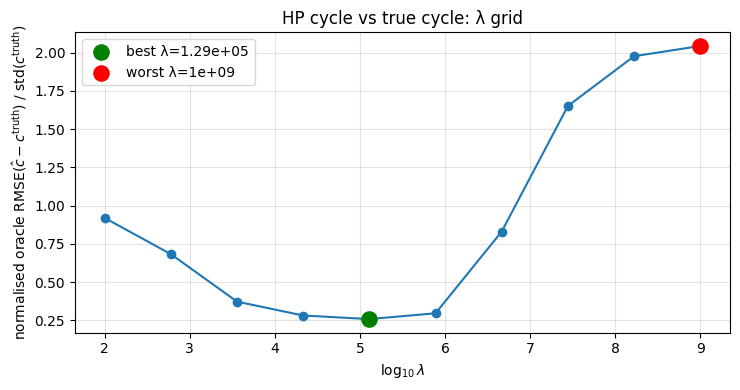

In [3]:
fig1, ax = plt.subplots(figsize=(7.5, 4.0))
xlog = np.log10(lambda_grid)
ax.plot(xlog, rmse_oracle_norm, marker="o", color="C0")
ax.scatter(xlog[idx_best], rmse_oracle_norm[idx_best], color="green", s=120, zorder=5, label=f"best λ={lambda_best:.3g}")
ax.scatter(xlog[idx_worst], rmse_oracle_norm[idx_worst], color="red", s=120, zorder=5, label=f"worst λ={lambda_worst:.3g}")
ax.set_xlabel(r"$\log_{10}\lambda$")
ax.set_ylabel(r"normalised oracle RMSE($\hat c - c^{\mathrm{truth}}$) / std($c^{\mathrm{truth}}$)")
ax.set_title("HP cycle vs true cycle: λ grid")
ax.grid(True, alpha=0.35)
ax.legend(loc="best")
fig1.tight_layout()
fig1.savefig("demos/rd_hpfilter_mcp_extra/rmse_vs_loglambda.png", dpi=140)
plt.show()

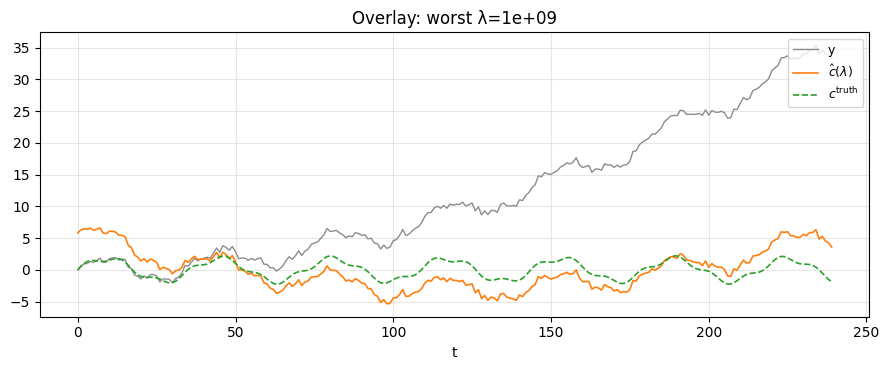

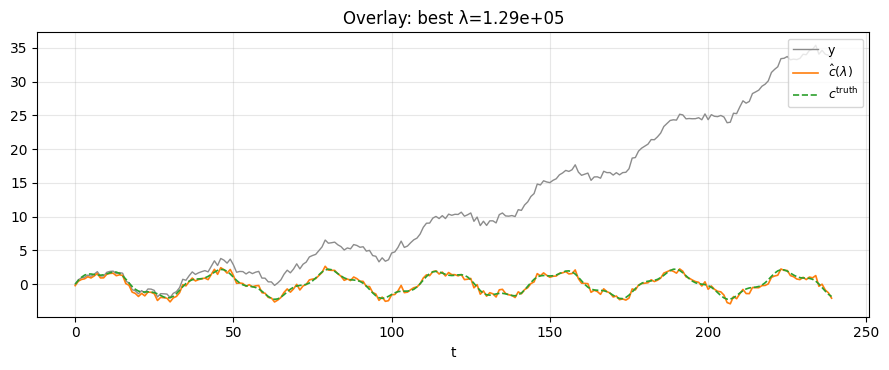

In [4]:
def plot_overlay(chat, title_suffix: str, fname: str) -> None:
    fig, ax = plt.subplots(figsize=(9.0, 3.8))
    ax.plot(t, y, color="0.55", lw=1.0, label="y")
    ax.plot(t, chat, color="C1", lw=1.2, label=r"$\hat c(\lambda)$")
    ax.plot(t, c_truth, color="C2", lw=1.2, ls="--", label=r"$c^{\mathrm{truth}}$")
    ax.set_title("Overlay: " + title_suffix)
    ax.set_xlabel("t")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(fname, dpi=140)
    plt.show()


plot_overlay(chat_worst, f"worst λ={lambda_worst:.3g}", "demos/rd_hpfilter_mcp_extra/overlay_worst_lambda.png")
plot_overlay(chat_best, f"best λ={lambda_best:.3g}", "demos/rd_hpfilter_mcp_extra/overlay_best_lambda.png")

In [5]:
# Diagnostics merged into HP/grid cell above.

## λ too small vs too large (arrays from the print block)

Inspect the printed **`lambda_grid`**, **`rmse_oracle_norm`**, **`rmse_oracle_norm[:3]`** (smallest λ), and **`rmse_oracle_norm[-3:]`** (largest λ), plus **`lambda_best`** / **`lambda_worst`**.

- **λ too small** (left end of **`log10 λ`**, e.g. first few entries of **`lambda_grid`**): the smoothness penalty on **`ĝ`** is weak, so **`ĝ`** hugs **`y`** and **`ĉ = y − ĝ`** is damped. True high-frequency **`c_truth`** and noise are partly absorbed into **`ĝ`**, inflating **`‖ĉ − c_truth‖`**—often visible as relatively **large** **`rmse_oracle_norm[:3]`** compared to the interior optimum.

- **λ too large** (right end): **`ĝ`** is almost linear/low-order and cannot bend enough to track the **true** smooth convex **`g_truth`** hidden inside **`y`**. Residual low-frequency structure leaks into **`ĉ`**, so **`ĉ`** no longer matches the **narrow-band** **`c_truth`**—see elevated **`rmse_oracle_norm[-3:]`**.

- **Intermediate λ**: curvature regularisation on **`ĝ`** is comparable to the **second-difference scale** of **`g_truth`**, so **`ĉ`** aligns best with **`c_truth`** (**minimum** **`rmse_oracle_norm`** at **`lambda_best`**; **`lambda_worst`** marks the grid extreme with largest error).